# Práctica 2 — Clasificación de números pares e impares en MNIST

Se parte del modelo de la práctica 1 (aplanado y una capa densa de 128 neuronas ReLU) y se adapta su salida a dos clases: **0 = par** (0, 2, 4, 6, 8) y **1 = impar** (1, 3, 5, 7, 9). Se comparan cuatro alternativas controladas: el modelo adaptado con 10 épocas, el mismo con más tiempo y parada temprana, una capa densa adicional y esa misma capa con regularización Dropout. Se conserva Adam y el lote 128 de la mejor configuración de la práctica 1.

La selección se realiza **exclusivamente con validación**; el test de MNIST se utiliza una sola vez, al final, para estimar el rendimiento del modelo elegido. Clasificar imágenes manuscritas ambiguas no permite garantizar una exactitud del 100 % fuera de la muestra.

In [1]:
import gc
import os
import time
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name != 'Practica-2' and (BASE_DIR / 'Practica-2').is_dir():
    BASE_DIR = BASE_DIR / 'Practica-2'
os.environ['KERAS_HOME'] = str(BASE_DIR / '.keras')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
BATCH_SIZE = 128
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.style.use('seaborn-v0_8-whitegrid')
print('TensorFlow:', tf.__version__)
print('Dispositivos:', tf.config.list_physical_devices())

TensorFlow: 2.20.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Datos y separación

Se reutilizan las 60 000 imágenes de entrenamiento y las 10 000 de test originales de la práctica 1. Se apartan **3 000 pares y 3 000 impares** del entrenamiento original como validación mediante una semilla fija; las otras 54 000 imágenes se utilizan para ajustar los pesos. Las etiquetas originales se conservan para diagnosticar los errores por dígito. La conversión $y_{bin}=y_{dígito}\bmod 2$ evita confundir las clases 0/1 con los propios dígitos 0 y 1. No hay solapamiento entre entrenamiento, validación y test.

In [2]:
(images_train, digits_train), (images_test, digits_test) = tf.keras.datasets.mnist.load_data()
if images_train.shape != (60_000, 28, 28) or images_test.shape != (10_000, 28, 28):
    raise ValueError('Dimensiones inesperadas en MNIST')
if not (np.isfinite(images_train).all() and np.isfinite(images_test).all()):
    raise ValueError('Las imágenes contienen valores no finitos')
if not (np.isin(digits_train, np.arange(10)).all() and np.isin(digits_test, np.arange(10)).all()):
    raise ValueError('Las etiquetas deben representar dígitos entre 0 y 9')

rng = np.random.default_rng(SEED)
validation_indices = np.concatenate([
    rng.permutation(np.flatnonzero(digits_train % 2 == parity))[:3_000]
    for parity in (0, 1)
])
validation_indices = rng.permutation(validation_indices)
fit_mask = np.ones(len(digits_train), dtype=bool)
fit_mask[validation_indices] = False

x_fit = images_train[fit_mask].astype('float32') / 255.0
x_val = images_train[validation_indices].astype('float32') / 255.0
x_test = images_test.astype('float32') / 255.0
y_fit = (digits_train[fit_mask] % 2).astype('int32')
y_val = (digits_train[validation_indices] % 2).astype('int32')
y_test = (digits_test % 2).astype('int32')

for name, x, y in (('Entrenamiento', x_fit, y_fit), ('Validación', x_val, y_val), ('Test', x_test, y_test)):
    print(f'{name}: imágenes={x.shape}, par/impar={np.bincount(y, minlength=2)}, rango=[{x.min():.1f}, {x.max():.1f}]')
assert len(x_fit) + len(x_val) == 60_000 and len(x_test) == 10_000
assert len(np.intersect1d(np.flatnonzero(fit_mask), validation_indices)) == 0

Entrenamiento: imágenes=(54000, 28, 28), par/impar=[26492 27508], rango=[0.0, 1.0]
Validación: imágenes=(6000, 28, 28), par/impar=[3000 3000], rango=[0.0, 1.0]
Test: imágenes=(10000, 28, 28), par/impar=[4926 5074], rango=[0.0, 1.0]


## 2. Arquitecturas y métricas

Respecto a la salida *softmax* de diez neuronas de la práctica 1, para este problema binario se utiliza **una neurona sigmoide**, entropía cruzada binaria y umbral de decisión 0,5. Las imágenes y el preprocesamiento son idénticos. Una capa adicional puede aprender combinaciones más complejas de trazos; Dropout (0,2) podría reducir el sobreajuste, aunque también puede perjudicar si la capacidad efectiva resulta insuficiente. La matriz de confusión tiene filas reales y columnas predichas, en orden par, impar.

In [3]:
CONFIGURATIONS = [
    {'name': 'base-10', 'hidden': (128,), 'dropout': 0.0, 'epochs': 10, 'early_stop': False},
    {'name': 'base-20-stop', 'hidden': (128,), 'dropout': 0.0, 'epochs': 20, 'early_stop': True},
    {'name': 'densa-20-stop', 'hidden': (128, 64), 'dropout': 0.0, 'epochs': 20, 'early_stop': True},
    {'name': 'densa-dropout-20-stop', 'hidden': (128, 64), 'dropout': 0.2, 'epochs': 20, 'early_stop': True},
]

def build_model(config):
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for units in config['hidden']:
        layers.append(tf.keras.layers.Dense(units, activation='relu'))
        if config['dropout']:
            layers.append(tf.keras.layers.Dropout(config['dropout']))
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model

def evaluate_predictions(model, x, y):
    probabilities = model.predict(x, batch_size=512, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype('int32')
    matrix = np.zeros((2, 2), dtype=np.int64)
    np.add.at(matrix, (y, predictions), 1)
    errors = int(np.count_nonzero(predictions != y))
    accuracy = float(np.mean(predictions == y))
    if matrix.sum() != len(y) or errors != len(y) - np.trace(matrix):
        raise RuntimeError('Las métricas y la matriz de confusión no concuerdan')
    return accuracy, errors, matrix, predictions

pd.DataFrame(CONFIGURATIONS)

,name,hidden,dropout,epochs,early_stop
0,base-10,"(128,)",0.0,10,False
1,base-20-stop,"(128,)",0.0,20,True
2,densa-20-stop,"(128, 64)",0.0,20,True
3,densa-dropout-20-stop,"(128, 64)",0.2,20,True


## 3. Experimentos y elección sin mirar el test

Todas las configuraciones comienzan con la misma semilla y usan Adam con lotes de 128. El tiempo incluye solo `fit`. La primera alternativa reproduce las 10 épocas de la práctica 1; las otras permiten hasta 20 épocas, con parada temprana al no mejorar la pérdida de validación durante 4 épocas y restauración de los mejores pesos. Se comparan mediante exactitud de validación; en caso de empate, menor pérdida de validación y luego menor tiempo. Se guardan también exactitud, errores, tiempo e historiales, así como matrices de confusión en entrenamiento y validación. La métrica de entrenamiento tras `fit` se calcula sin Dropout para una comparación homogénea.

In [4]:
results = []
histories = {}
confusion_matrices = {}
model_path = BASE_DIR / 'mejor_modelo_paridad.keras'
best_score = (-np.inf, -np.inf, -np.inf)
best_name = None

for config in CONFIGURATIONS:
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(config)
    callbacks = ([tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True
    )] if config['early_stop'] else [])
    start = time.perf_counter()
    history = model.fit(
        x_fit, y_fit, validation_data=(x_val, y_val),
        epochs=config['epochs'], batch_size=BATCH_SIZE, callbacks=callbacks,
        shuffle=True, verbose=0,
    )
    elapsed = time.perf_counter() - start
    train_accuracy, train_errors, train_matrix, _ = evaluate_predictions(model, x_fit, y_fit)
    val_accuracy, val_errors, val_matrix, _ = evaluate_predictions(model, x_val, y_val)
    val_loss = float(model.evaluate(x_val, y_val, batch_size=512, verbose=0)[0])
    result = {
        'configuration': config['name'], 'hidden': str(config['hidden']),
        'dropout': config['dropout'], 'max_epochs': config['epochs'],
        'epochs_run': len(history.history['loss']),
        'restored_epoch': int(np.argmin(history.history['val_loss']) + 1) if config['early_stop'] else len(history.history['loss']),
        'train_accuracy': train_accuracy, 'train_errors': train_errors,
        'val_accuracy': val_accuracy, 'val_errors': val_errors,
        'val_loss': val_loss, 'train_seconds': elapsed,
        'accuracy_gap': train_accuracy - val_accuracy,
    }
    results.append(result)
    histories[config['name']] = history.history
    confusion_matrices[f"{config['name']}_train"] = train_matrix
    confusion_matrices[f"{config['name']}_val"] = val_matrix
    score = (val_accuracy, -val_loss, -elapsed)
    if score > best_score:
        model.save(model_path)
        best_score, best_name = score, config['name']
    print(
        f"{config['name']:<23} train={train_accuracy:.4%} ({train_errors} errores) "
        f"val={val_accuracy:.4%} ({val_errors} errores) "
        f"épocas={len(history.history['loss']):>2} tiempo={elapsed:.2f}s"
    )
    del model

results_df = pd.DataFrame(results).sort_values(
    ['val_accuracy', 'val_loss', 'train_seconds'], ascending=[False, True, True]
).reset_index(drop=True)
results_df.to_csv(BASE_DIR / 'resultados_configuraciones.csv', index=False)
np.savez_compressed(BASE_DIR / 'matrices_confusion.npz', **confusion_matrices)
assert best_name == results_df.iloc[0]['configuration']
display(results_df.round(4))
print('Seleccionado por validación:', best_name)

2026-09-28 18:21:02.549689: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


base-10                 train=99.3981% (325 errores) val=98.0667% (116 errores) épocas=10 tiempo=3.26s


2026-09-28 18:21:12.198319: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


base-20-stop            train=99.8481% (82 errores) val=98.2167% (107 errores) épocas=20 tiempo=6.08s


densa-20-stop           train=98.7037% (700 errores) val=97.8667% (128 errores) épocas= 6 tiempo=2.35s


densa-dropout-20-stop   train=99.5593% (238 errores) val=98.2500% (105 errores) épocas=12 tiempo=4.63s


2026-09-28 18:21:19.872492: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,configuration,hidden,dropout,max_epochs,epochs_run,restored_epoch,train_accuracy,train_errors,val_accuracy,val_errors,val_loss,train_seconds,accuracy_gap
0,densa-dropout-20-stop,"(128, 64)",0.2,20,12,8,0.9956,238,0.9825,105,0.0597,4.6331,0.0131
1,base-20-stop,"(128,)",0.0,20,20,16,0.9985,82,0.9822,107,0.0598,6.0781,0.0163
2,base-10,"(128,)",0.0,10,10,10,0.9940,325,0.9807,116,0.0652,3.2559,0.0133
3,densa-20-stop,"(128, 64)",0.0,20,6,2,0.9870,700,0.9787,128,0.0653,2.3541,0.0084


Seleccionado por validación: densa-dropout-20-stop


## 4. Comparación visual

La brecha entrenamiento–validación ayuda a identificar sobreajuste; la pérdida y la exactitud por época muestran el efecto de ampliar el entrenamiento y de añadir capacidad o regularización. Los tiempos varían según el equipo.

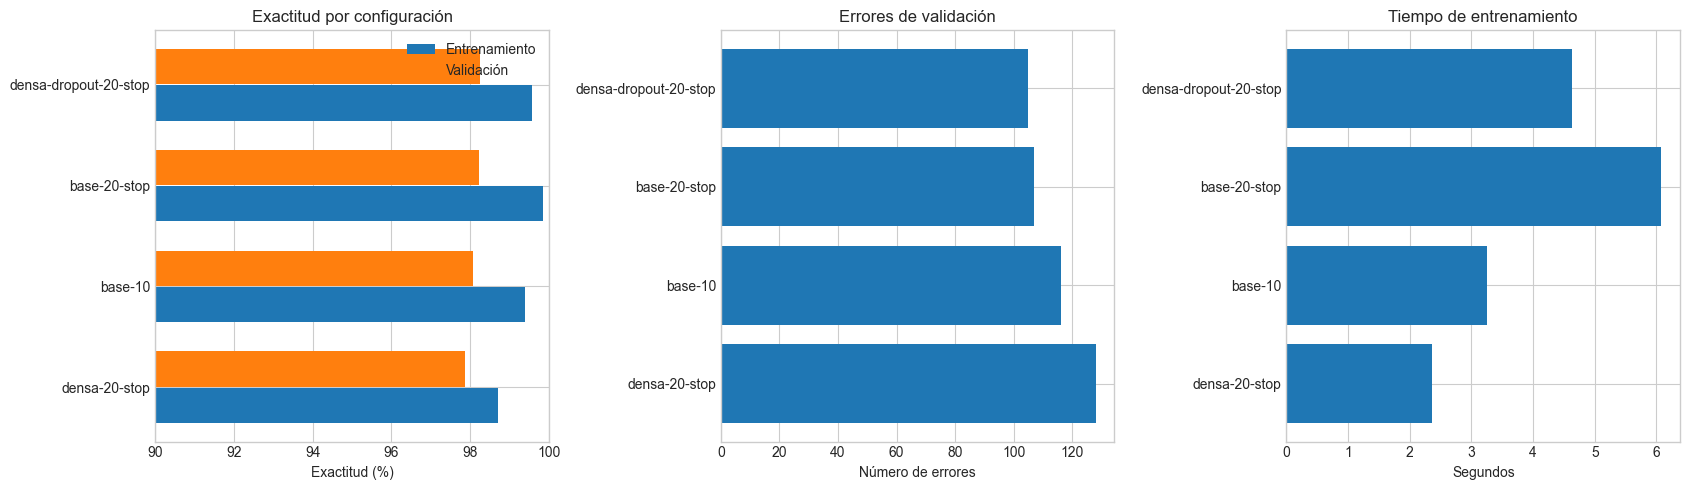

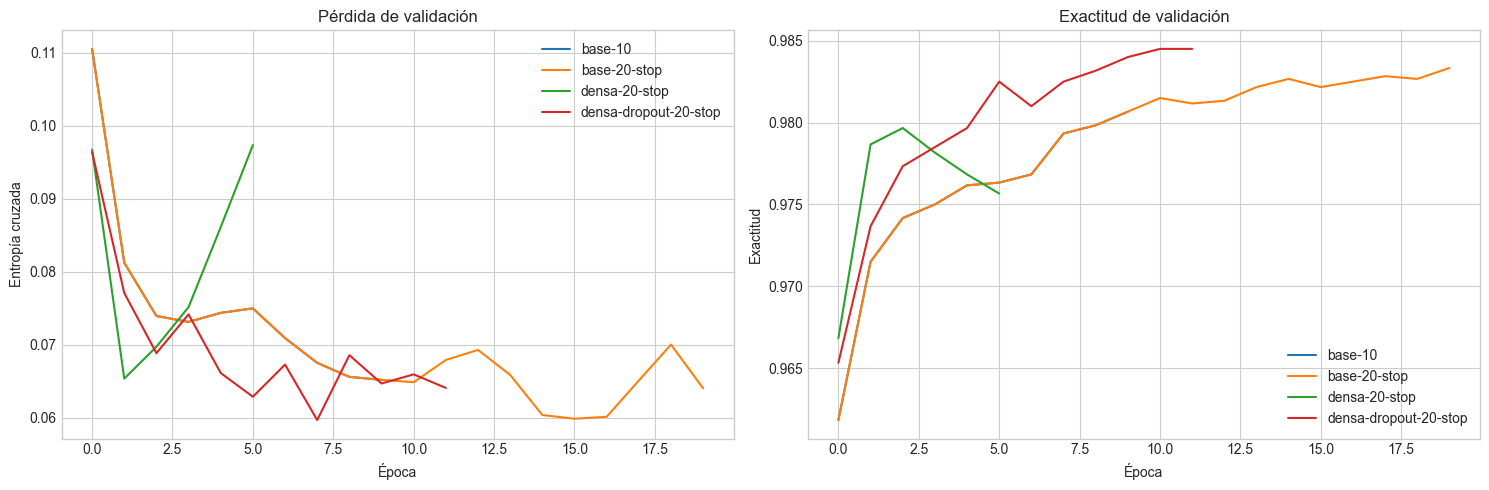

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_df = results_df.sort_values('val_accuracy')
positions = np.arange(len(plot_df))
axes[0].barh(positions - 0.18, plot_df['train_accuracy'] * 100, height=0.35, label='Entrenamiento')
axes[0].barh(positions + 0.18, plot_df['val_accuracy'] * 100, height=0.35, label='Validación')
axes[0].set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Exactitud (%)', title='Exactitud por configuración', xlim=(90, 100))
axes[0].legend()
axes[1].barh(positions, plot_df['val_errors'])
axes[1].set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Número de errores', title='Errores de validación')
axes[2].barh(positions, plot_df['train_seconds'])
axes[2].set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Segundos', title='Tiempo de entrenamiento')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, history in histories.items():
    axes[0].plot(history['val_loss'], label=name)
    axes[1].plot(history['val_accuracy'], label=name)
axes[0].set(xlabel='Época', ylabel='Entropía cruzada', title='Pérdida de validación')
axes[1].set(xlabel='Época', ylabel='Exactitud', title='Exactitud de validación')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

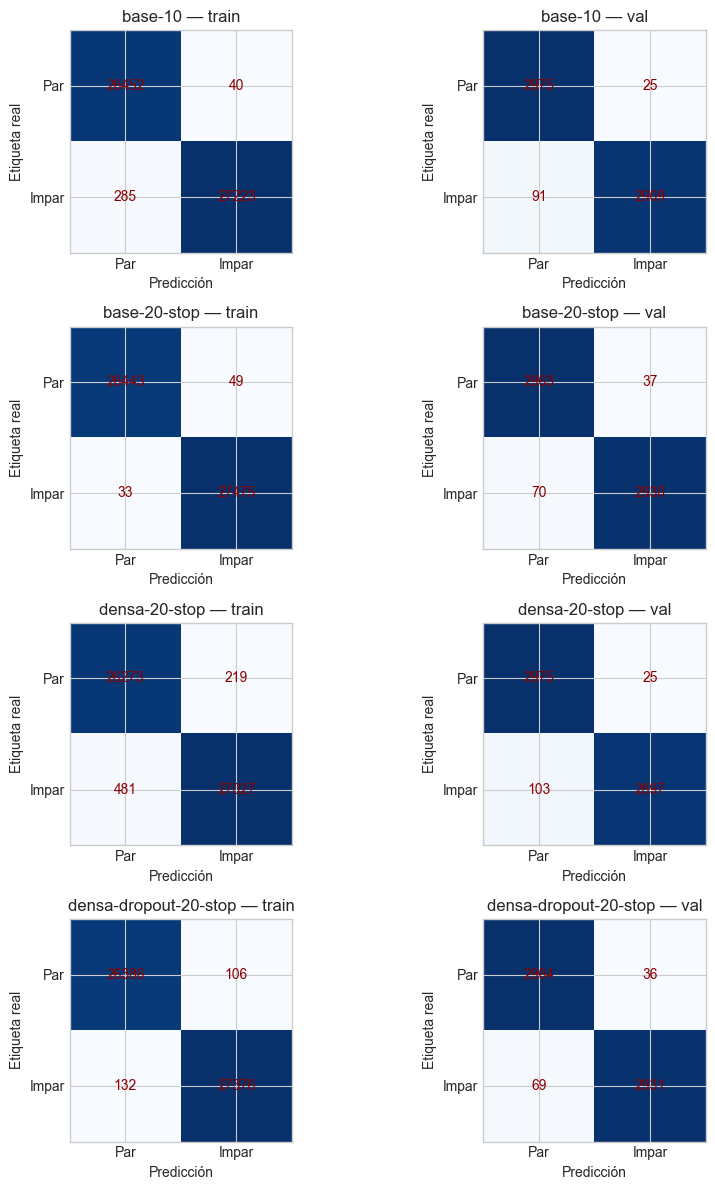

In [6]:
fig, axes = plt.subplots(len(CONFIGURATIONS), 2, figsize=(9, 3 * len(CONFIGURATIONS)))
for row, config in enumerate(CONFIGURATIONS):
    for col, split in enumerate(('train', 'val')):
        matrix = confusion_matrices[f"{config['name']}_{split}"]
        ax = axes[row, col]
        ax.imshow(matrix, cmap='Blues')
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{matrix[i, j]}', ha='center', va='center', color='darkred')
        ax.set(xticks=(0, 1), yticks=(0, 1), xticklabels=('Par', 'Impar'),
               yticklabels=('Par', 'Impar'), xlabel='Predicción', ylabel='Etiqueta real',
               title=f"{config['name']} — {split}")
plt.tight_layout()
plt.show()

## 5. Evaluación final y persistencia

Solo después de seleccionar el ganador se recarga el fichero `.keras` y se evalúa el test intacto. Se verifica la coincidencia de sus métricas de validación antes de utilizar el test. Un desglose por dígito permite comprobar si una de las dos clases o un dígito concreto causa más errores. Para reutilizar el modelo, normalizar cualquier imagen de 28 × 28 a `[0,1]` y clasificar como **impar** si la probabilidad devuelta es al menos 0,5.

In [7]:
best_model = tf.keras.models.load_model(model_path)
best_row = results_df.iloc[0]
reloaded_accuracy, reloaded_errors, reloaded_matrix, _ = evaluate_predictions(best_model, x_val, y_val)
if not np.isclose(reloaded_accuracy, best_row['val_accuracy']) or reloaded_errors != best_row['val_errors']:
    raise RuntimeError('El modelo recuperado no reproduce el resultado de validación')

test_accuracy, test_errors, test_matrix, test_predictions = evaluate_predictions(best_model, x_test, y_test)
assert int(np.trace(test_matrix)) + test_errors == len(y_test)
print('Modelo guardado:', model_path)
print(f"Validación: exactitud={reloaded_accuracy:.4%}; errores={reloaded_errors}/{len(y_val)}")
print(f'Test: exactitud={test_accuracy:.4%}; errores={test_errors}/{len(y_test)}')
print('Matriz de confusión de test (filas reales; columnas predichas):')
display(pd.DataFrame(test_matrix, index=['Par real', 'Impar real'], columns=['Par predicho', 'Impar predicho']))

per_digit = pd.DataFrame({
    'digit': digits_test, 'correct': test_predictions == y_test
}).groupby('digit')['correct'].agg(['count', 'sum'])
per_digit['errors'] = per_digit['count'] - per_digit['sum']
per_digit['accuracy'] = per_digit['sum'] / per_digit['count']
display(per_digit[['count', 'errors', 'accuracy']].rename(columns={'count': 'ejemplos', 'errors': 'errores', 'accuracy': 'exactitud'}))

Modelo guardado: /Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/Practica-2/mejor_modelo_paridad.keras
Validación: exactitud=98.2500%; errores=105/6000
Test: exactitud=98.5600%; errores=144/10000
Matriz de confusión de test (filas reales; columnas predichas):


,Par predicho,Impar predicho
Par real,4857,69
Impar real,75,4999


,ejemplos,errores,exactitud
digit,,,
0,980,6,0.993878
1,1135,13,0.988546
2,1032,16,0.984496
3,1010,7,0.993069
4,982,17,0.982688
5,892,19,0.978700
6,958,7,0.992693
7,1028,11,0.989300
8,974,23,0.976386


## 6. Interpretación y conclusiones

| Configuración | Épocas ejecutadas (pesos usados) | Exactitud train | Exactitud validación | Errores de validación | Tiempo CPU |
|:--|--:|--:|--:|--:|--:|
| Base, 10 épocas | 10 (10) | 99,398 % | 98,067 % | 116 | 3,26 s |
| Base, hasta 20 con parada | 20 (16) | 99,848 % | 98,217 % | 107 | 6,08 s |
| Dos densas, sin Dropout | 6 (2) | 98,704 % | 97,867 % | 128 | 2,35 s |
| **Dos densas, Dropout 0,2** | **12 (8)** | **99,559 %** | **98,250 %** | **105** | **4,63 s** |

1. **Cambiar la salida es indispensable:** dos clases requieren una salida sigmoide y pérdida binaria, no las diez probabilidades originales. Con estos cambios mínimos, el modelo base ya clasifica correctamente 5 884 de los 6 000 ejemplos de validación.
2. **Más épocas en el modelo base** mejoran la validación en 9 ejemplos, pero elevan la brecha entre train y validación de 1,331 a 1,631 puntos porcentuales: seguir optimizando el entrenamiento puede empeorar la generalización. La parada temprana restaura los pesos de la época 16.
3. **Añadir una capa densa sin regularizar** no aporta una mejora automática: su menor pérdida de validación se alcanza en la época 2 y solo clasifica bien 5 872/6 000 ejemplos. Una arquitectura más grande no garantiza una mejor solución con los mismos hiperparámetros.
4. **Dropout 0,2** mejora al modelo profundo sin regularizar en 23 ejemplos de validación y reduce la brecha train–validación frente a la base de 20 épocas (1,309 frente a 1,631 puntos). Es la mejor configuración **entre las probadas**: Adam, lote 128, capas ocultas de 128 y 64 ReLU, Dropout 0,2 después de cada capa y salida sigmoide. Sus pesos seleccionados corresponden a la época 8. Frente a la base de 20 épocas gana solo **2 ejemplos entre 6 000**: esta ventaja pequeña no demuestra que siempre sea superior y se necesitarían otras semillas o más datos para establecer su robustez.
5. **Test independiente:** el fichero guardado y recargado obtiene **98,56 %** de exactitud (9 856 aciertos y **144 errores** de 10 000). La matriz de confusión contiene 69 pares clasificados como impares y 75 impares clasificados como pares. Los dígitos 8 y 9 concentran 23 y 25 errores, respectivamente. No se usó test para elegir configuración: su resultado puede diferir del de validación por variación muestral.

La paridad no se lee directamente de los píxeles: la red debe distinguir grafías manuscritas que pueden resultar ambiguas. La configuración elegida optimiza la **exactitud de validación de este conjunto de alternativas**, no garantiza acertar todas las imágenes futuras. El artefacto persistido en `mejor_modelo_paridad.keras` acepta imágenes `float32` de forma `(28, 28)` normalizadas a `[0,1]` y devuelve una probabilidad de **impar** (umbral 0,5).